In [ ]:
import kagglehub
path = kagglehub.dataset_download("reubensuju/celeb-df-v2")

Using Colab cache for faster access to the 'celeb-df-v2' dataset.


In [ ]:
import io
import os
import random
import shutil
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm
import cv2
from sklearn.model_selection import train_test_split

In [ ]:
import base64
import json

import matplotlib
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [ ]:
from sklearn.metrics import roc_curve

In [ ]:
import time

import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from torchvision.models import EfficientNet_B4_Weights, efficientnet_b4

In [ ]:
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms

In [ ]:
@dataclass(frozen=True)
class Config:
    seed: int = 42
    image_size: int = 380
    batch_size: int = 8
    num_workers: int = 2
    samples_per_epoch: int = 12_000
    learning_rate: float = 1e-4
    weight_decay: float = 1e-4
    max_epochs: int = 8
    patience: int = 2


CFG = Config()

In [ ]:
def seed_everything(seed: int) -> None:
    """Make runs reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
def resolve_frame_path(old_path: str) -> str:
    """Map a frame path from an old Colab session to its current location."""
    old_path = Path(old_path)
    if old_path.is_file():
        return str(old_path)

    parts = old_path.parts
    if "frames" not in parts:
        raise ValueError(f"No 'frames' folder in path: {old_path}")

    last_frames_idx = len(parts) - 1 - parts[::-1].index("frames")
    return str(FRAME_DIR.joinpath(*parts[last_frames_idx + 1:]))

In [ ]:
def find_missing_files(df: pd.DataFrame) -> list:
    """Return every frame path that does not exist on disk."""
    return [p for p in tqdm(df["frame_path"], desc="Checking files") if not os.path.isfile(p)]

In [ ]:
def check_video_leakage(df: pd.DataFrame) -> None:
    """Frames of one video must never be spread across train/val/test."""
    splits_per_video = df.groupby("video_path")["split"].nunique()
    leaked = splits_per_video[splits_per_video > 1]
    if len(leaked) > 0:
        raise RuntimeError(f"{len(leaked)} videos appear in more than one split!")

In [ ]:
def print_manifest_report(df: pd.DataFrame) -> None:
    print("Total frames:", len(df))
    print("\nFrames per split (is_fake: 0=real, 1=fake):")
    print(pd.crosstab(df["split"], df["is_fake"]))
    print("\nVideos per split:")
    print(df.groupby("split")["video_path"].nunique())

In [ ]:
def find_dataset_root(search_root: str = "/kaggle/input",
                      marker: str = "List_of_testing_videos.txt") -> Path:
    """Locate the Celeb-DF folder wherever Kaggle mounted it."""
    for dirpath, _, filenames in os.walk(search_root):
        if marker in filenames:
            return Path(dirpath)
    raise FileNotFoundError(
        "Celeb-DF not found. Use 'Add Input' and attach reubensuju/celeb-df-v2."
    )

In [ ]:
DATA_DIR = find_dataset_root()
WORK_DIR = Path("/kaggle/working")

FRAME_DIR = WORK_DIR / "frames"
MANIFEST_DIR = WORK_DIR / "manifests"
MODEL_DIR = WORK_DIR / "models"
RESULTS_DIR = WORK_DIR / "results"
FRAMES_PER_VIDEO = 5

for folder in (FRAME_DIR, MANIFEST_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset root:", DATA_DIR)
print("Content:", sorted(os.listdir(DATA_DIR)))
print("CUDA available:", torch.cuda.is_available())

Dataset root: /kaggle/input/celeb-df-v2
Content: ['Celeb-real', 'Celeb-synthesis', 'List_of_testing_videos.txt', 'YouTube-real']
CUDA available: True


In [ ]:
def read_official_test_list(data_dir: Path) -> pd.DataFrame:
    """Official Celeb-DF test videos. Source label convention: 1 = real, 0 = fake."""
    rows = []
    with open(data_dir / "List_of_testing_videos.txt") as f:
        for line in f:
            parts = line.strip().split(maxsplit=1)
            if len(parts) == 2:
                rows.append({"path": parts[1], "label": int(parts[0])})
    return pd.DataFrame(rows)

In [ ]:
VIDEO_FOLDERS = {"Celeb-real": 1, "YouTube-real": 1, "Celeb-synthesis": 0}


def collect_all_videos(data_dir: Path) -> pd.DataFrame:
    """List every .mp4 in the dataset with its label (1 = real, 0 = fake)."""
    rows = []
    for folder, label in VIDEO_FOLDERS.items():
        for name in sorted(os.listdir(data_dir / folder)):
            if name.lower().endswith(".mp4"):
                rows.append({"path": f"{folder}/{name}", "label": label})
    return pd.DataFrame(rows)

In [ ]:
def split_videos(all_df: pd.DataFrame, test_df: pd.DataFrame, seed: int) -> dict:
    """Official test list = test; the rest is split 80/20 into train/val by video."""
    remaining = all_df[~all_df["path"].isin(set(test_df["path"]))]
    train_df, val_df = train_test_split(
        remaining, test_size=0.20, random_state=seed, stratify=remaining["label"]
    )
    return {"train": train_df, "val": val_df, "test": test_df}

In [ ]:
def extract_video_frames(video_path: Path, out_dir: Path, n_frames: int) -> list:
    """Save `n_frames` evenly spaced frames; return their (path, frame_idx) pairs.
    Frames that already exist are reused, so the cell can be re-run safely."""
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if cap.isOpened() else 0
    if total < n_frames:
        cap.release()
        return []

    indices = np.linspace(int(total * 0.1), int(total * 0.9), n_frames, dtype=int)
    out_dir.mkdir(parents=True, exist_ok=True)

    saved = []
    for idx in indices:
        out_path = out_dir / f"{video_path.stem}_f{idx}.jpg"
        if not out_path.is_file():
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()
            if not ok:
                continue
            cv2.imwrite(str(out_path), frame, [cv2.IMWRITE_JPEG_QUALITY, 95])
        saved.append((str(out_path), int(idx)))

    cap.release()
    return saved

In [ ]:
def extract_split_frames(split_df: pd.DataFrame, split: str, data_dir: Path,
                         frame_dir: Path, n_frames: int):
    """Extract frames for every video in a split. Returns (records, failed_videos)."""
    records, failed = [], []
    for row in tqdm(split_df.itertuples(index=False), total=len(split_df), desc=split):
        folder = Path(row.path).parent.name
        saved = extract_video_frames(
            data_dir / row.path, frame_dir / split / folder, n_frames
        )
        if not saved:
            failed.append(row.path)
            continue
        records += [
            {"frame_path": p, "video_path": row.path, "label": int(row.label),
             "split": split, "frame_idx": i}
            for p, i in saved
        ]
    return records, failed

In [ ]:
def build_frames_manifest(data_dir: Path, frame_dir: Path, manifest_path: Path,
                          n_frames: int, seed: int) -> pd.DataFrame:
    """Split videos, extract frames, and save frames_manifest.csv."""
    splits = split_videos(
        collect_all_videos(data_dir), read_official_test_list(data_dir), seed
    )
    all_records, all_failed = [], []
    for split, split_df in splits.items():
        records, failed = extract_split_frames(split_df, split, data_dir, frame_dir, n_frames)
        all_records += records
        all_failed += failed

    manifest = pd.DataFrame(all_records)
    manifest.to_csv(manifest_path, index=False)
    print("Failed videos:", all_failed)
    return manifest

In [ ]:
REQUIRED_COLUMNS = {"frame_path", "label", "split", "video_path"}


def load_frames_manifest(csv_path: Path) -> pd.DataFrame:
    """Load the manifest and add the `is_fake` target (fake=1, real=0)."""
    df = pd.read_csv(csv_path)

    missing = REQUIRED_COLUMNS - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    if not set(df["label"].unique()) <= {0, 1}:
        raise ValueError("`label` must contain only 0 (fake) and 1 (real).")

    df["is_fake"] = (df["label"] == 0).astype(int)
    return df

In [ ]:
seed_everything(CFG.seed)

manifest_path = MANIFEST_DIR / "frames_manifest.csv"
if not manifest_path.is_file():
    build_frames_manifest(DATA_DIR, FRAME_DIR, manifest_path, FRAMES_PER_VIDEO, CFG.seed)
else:
    print("Manifest already exists, skipping extraction.")

train:   0%|          | 0/4808 [00:00<?, ?it/s]

val:   0%|          | 0/1203 [00:00<?, ?it/s]

test:   0%|          | 0/518 [00:00<?, ?it/s]

Failed videos: ['Celeb-real/id27_0005.mp4']


In [ ]:
frames_df = load_frames_manifest(manifest_path)

missing = find_missing_files(frames_df)
if missing:
    raise FileNotFoundError(f"{len(missing)} frames missing, e.g. {missing[:3]}")

check_video_leakage(frames_df)
print_manifest_report(frames_df)
print("\nDataset validation passed!")

Checking files:   0%|          | 0/32640 [00:00<?, ?it/s]

Total frames: 32640

Frames per split (is_fake: 0=real, 1=fake):
is_fake     0      1
split               
test      890   1700
train    2845  21190
val       710   5305

Videos per split:
split
test      518
train    4807
val      1203
Name: video_path, dtype: int64

Dataset validation passed!


In [ ]:
def copy_frames_to_local(src: Path, dst: Path) -> None:
    shutil.copytree(src, dst, dirs_exist_ok=True)


LOCAL_FRAME_DIR = Path("/content/frames_local")
copy_frames_to_local(FRAME_DIR, LOCAL_FRAME_DIR)
FRAME_DIR = LOCAL_FRAME_DIR

In [ ]:
class RandomJPEG:
    """Randomly re-compress an image as JPEG (simulates sharing on social apps)."""

    def __init__(self, quality=(60, 95), p: float = 0.3):
        self.quality = quality
        self.p = p

    def __call__(self, image: Image.Image) -> Image.Image:
        if random.random() > self.p:
            return image
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=random.randint(*self.quality))
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def build_transforms(image_size: int):
    """Return (train_transform, eval_transform). The whole frame is kept (no face crop)."""
    train_tf = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        RandomJPEG(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_tf, eval_tf

In [ ]:
class FrameDataset(Dataset):
    """Returns (image_tensor, target) where target = 1.0 for fake and 0.0 for real."""

    def __init__(self, df: pd.DataFrame, transform):
        self.paths = df["frame_path"].tolist()
        self.targets = df["is_fake"].astype("float32").tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        image = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(image), torch.tensor(self.targets[idx])

In [ ]:
def make_balanced_sampler(df: pd.DataFrame, num_samples: int) -> WeightedRandomSampler:
    """Draw real and fake frames with equal probability."""
    class_counts = df["is_fake"].value_counts()
    weights = df["is_fake"].map(1.0 / class_counts).to_numpy()
    return WeightedRandomSampler(
        weights=torch.as_tensor(weights, dtype=torch.double),
        num_samples=num_samples,
        replacement=True,
    )

In [ ]:
def build_dataloaders(df: pd.DataFrame, cfg: Config) -> dict:
    """Build train / val / test DataLoaders from the manifest."""
    train_tf, eval_tf = build_transforms(cfg.image_size)
    parts = {s: df[df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}

    common = dict(
        batch_size=cfg.batch_size,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    return {
        "train": DataLoader(
            FrameDataset(parts["train"], train_tf),
            sampler=make_balanced_sampler(parts["train"], cfg.samples_per_epoch),
            **common,
        ),
        "val": DataLoader(FrameDataset(parts["val"], eval_tf), shuffle=False, **common),
        "test": DataLoader(FrameDataset(parts["test"], eval_tf), shuffle=False, **common),
    }

In [ ]:
def inspect_first_batch(loader: DataLoader) -> None:
    images, targets = next(iter(loader))
    print("Images:", tuple(images.shape), "| dtype:", images.dtype)
    print("Targets:", targets.tolist())
    print("Fake fraction in batch:", targets.mean().item())
    print("Value range:", round(images.min().item(), 2), "to", round(images.max().item(), 2))

In [ ]:
loaders = build_dataloaders(frames_df, CFG)

for name, loader in loaders.items():
    print(f"{name}: {len(loader.dataset)} frames, {len(loader)} batches")

inspect_first_batch(loaders["train"])

train: 24035 frames, 1500 batches
val: 6015 frames, 752 batches
test: 2590 frames, 324 batches
Images: (8, 3, 380, 380) | dtype: torch.float32
Targets: [1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0]
Fake fraction in batch: 0.5
Value range: -2.12 to 2.64


In [ ]:
def build_model() -> nn.Module:
    """EfficientNet-B4 (ImageNet weights) with one output logit: P(fake) = sigmoid(logit)."""
    model = efficientnet_b4(weights=EfficientNet_B4_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
    return model

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device) -> float:
    """One FP32 training pass. Stops immediately if the loss becomes NaN/Inf."""
    model.train()
    total_loss = 0.0
    for images, targets in tqdm(loader, desc="train", leave=False):
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images).squeeze(1), targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)

In [ ]:
@torch.no_grad()
def predict_scores(model, loader, criterion, device):
    """Return (targets, fake_probabilities, mean_loss) for a loader."""
    model.eval()
    all_targets, all_probs, total_loss = [], [], 0.0
    for images, targets in tqdm(loader, desc="eval", leave=False):
        logits = model(images.to(device)).squeeze(1)
        total_loss += criterion(logits, targets.to(device)).item()
        all_probs.append(torch.sigmoid(logits).cpu().numpy())
        all_targets.append(targets.numpy())
    return np.concatenate(all_targets), np.concatenate(all_probs), total_loss / len(loader)

In [ ]:
def compute_metrics(targets: np.ndarray, probs: np.ndarray, threshold: float = 0.5) -> dict:
    """Metrics with fake as the positive class. FPR = real images flagged as fake."""
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(targets, preds, labels=[0, 1]).ravel()
    return {
        "auc": roc_auc_score(targets, probs),
        "f1": f1_score(targets, preds, zero_division=0),
        "precision": precision_score(targets, preds, zero_division=0),
        "recall": recall_score(targets, preds, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
    }

In [ ]:
class EarlyStopping:
    """Tracks the best validation AUC and signals when to stop."""

    def __init__(self, patience: int):
        self.patience = patience
        self.best = -float("inf")
        self.bad_epochs = 0

    def update(self, score: float) -> bool:
        """Return True if `score` is a new best."""
        if score > self.best:
            self.best, self.bad_epochs = score, 0
            return True
        self.bad_epochs += 1
        return False

    @property
    def should_stop(self) -> bool:
        return self.bad_epochs >= self.patience

In [ ]:
def save_checkpoint(path: Path, model, optimizer, scheduler, epoch: int, stopper: EarlyStopping) -> None:
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "best_auc": stopper.best,
        "bad_epochs": stopper.bad_epochs,
    }, path)


def load_checkpoint(path: Path, model, optimizer, scheduler, stopper: EarlyStopping, device) -> int:
    """Restore a checkpoint and return the last completed epoch."""
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    stopper.best, stopper.bad_epochs = ckpt["best_auc"], ckpt["bad_epochs"]
    return ckpt["epoch"]

In [ ]:
def fit(model, loaders, optimizer, scheduler, criterion, device, cfg, model_dir: Path) -> pd.DataFrame:
    """Train with early stopping on validation AUC; resumes from last.pth if present."""
    stopper = EarlyStopping(cfg.patience)
    last_path, best_path = model_dir / "last.pth", model_dir / "best.pth"
    start_epoch = 0
    if last_path.is_file():
        start_epoch = load_checkpoint(last_path, model, optimizer, scheduler, stopper, device)
        print(f"Resumed after epoch {start_epoch}")

    history = []
    for epoch in range(start_epoch + 1, cfg.max_epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, loaders["train"], optimizer, criterion, device)
        targets, probs, val_loss = predict_scores(model, loaders["val"], criterion, device)
        metrics = compute_metrics(targets, probs)
        scheduler.step()

        if stopper.update(metrics["auc"]):
            torch.save(model.state_dict(), best_path)
        save_checkpoint(last_path, model, optimizer, scheduler, epoch, stopper)

        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, **metrics})
        print(f"Epoch {epoch} | {(time.time() - t0) / 60:.1f} min | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | AUC {metrics['auc']:.4f} | F1 {metrics['f1']:.4f} | "
              f"FPR {metrics['fpr']:.3f}")
        if stopper.should_stop:
            print("Early stopping.")
            break

    return pd.DataFrame(history)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = build_model().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.max_epochs)

print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Parameters: 17550409


#Model Training

In [ ]:
history_df = fit(model, loaders, optimizer, scheduler, criterion, device, CFG, MODEL_DIR)
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)

train:   0%|          | 0/1500 [00:00<?, ?it/s]

eval:   0%|          | 0/752 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eaf7a0763e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Epoch 1 | 9.4 min | train 0.4165 | val 0.1776 | AUC 0.9446 | F1 0.9643 | FPR 0.293


train:   0%|          | 0/1500 [00:00<?, ?it/s]

eval:   0%|          | 0/752 [00:00<?, ?it/s]

... (16 outputs left out)

Epoch 6 | 9.9 min | train 0.0846 | val 0.1935 | AUC 0.9693 | F1 0.9764 | FPR 0.249


train:   0%|          | 0/1500 [00:00<?, ?it/s]

eval:   0%|          | 0/752 [00:00<?, ?it/s]

Epoch 7 | 9.5 min | train 0.0727 | val 0.1902 | AUC 0.9684 | F1 0.9761 | FPR 0.211
Early stopping.


###________________________________________
#Evaluation
###________________________________________

In [ ]:
def load_best_model(model, path: Path, device) -> None:
    """Load the best checkpoint (highest validation AUC)."""
    model.load_state_dict(torch.load(path, map_location=device))
    model.eval()

In [ ]:
def collect_predictions(model, loader, criterion, device, split_df: pd.DataFrame) -> pd.DataFrame:
    """Frame-level predictions: one row per frame with video_path, target and fake score."""
    targets, probs, _ = predict_scores(model, loader, criterion, device)
    out = split_df[["video_path"]].reset_index(drop=True)
    out["target"] = targets.astype(int)
    out["score"] = probs
    return out

In [ ]:
def threshold_at_fpr(preds: pd.DataFrame, max_fpr: float = 0.05) -> float:
    """Lowest threshold whose false-positive rate (real flagged as fake) is <= max_fpr."""
    fpr, _, thresholds = roc_curve(preds["target"], preds["score"])
    best = np.where(fpr <= max_fpr)[0][-1]
    return float(min(thresholds[best], 1.0))

In [ ]:
def evaluate_predictions(preds: pd.DataFrame, threshold: float) -> dict:
    return compute_metrics(preds["target"].to_numpy(), preds["score"].to_numpy(), threshold)

In [ ]:
import json

load_best_model(model, MODEL_DIR / "best.pth", device)

val_preds = collect_predictions(model, loaders["val"], criterion, device, frames_df[frames_df["split"] == "val"])
test_preds = collect_predictions(model, loaders["test"], criterion, device, frames_df[frames_df["split"] == "test"])

threshold = threshold_at_fpr(val_preds, 0.05)

rows = {
    "threshold 0.5": evaluate_predictions(test_preds, 0.5),
    f"threshold {threshold:.3f}": evaluate_predictions(test_preds, threshold),
}
print(pd.DataFrame(rows).T.round(4))

test_preds.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
with open(RESULTS_DIR / "thresholds.json", "w") as f:
    json.dump({"threshold": threshold, "max_fpr": 0.05}, f)

eval:   0%|          | 0/752 [00:00<?, ?it/s]

eval:   0%|          | 0/324 [00:00<?, ?it/s]

                    auc      f1  precision  recall     fpr
threshold 0.5    0.9735  0.9401     0.9379  0.9424  0.1191
threshold 0.997  0.9735  0.8551     0.9832  0.7565  0.0247


In [ ]:
def threshold_at_recall(preds: pd.DataFrame, min_recall: float = 0.95) -> float:
    """Highest threshold that still catches at least `min_recall` of the fakes."""
    _, tpr, thresholds = roc_curve(preds["target"], preds["score"])
    first = np.where(tpr >= min_recall)[0][0]
    return float(min(thresholds[first], 1.0))


low = threshold_at_recall(val_preds, 0.95)
bands = pd.cut(test_preds["score"], [-np.inf, low, threshold, np.inf],
               labels=["real", "suspicious", "fake"], right=False)

print(f"low={low:.3f}, high={threshold:.3f}")
print(pd.crosstab(test_preds["target"].map({0: "real", 1: "fake"}), bands))

with open(RESULTS_DIR / "thresholds.json", "w") as f:
    json.dump({"low": low, "high": threshold, "max_fpr": 0.05, "min_recall": 0.95}, f)

low=0.799, high=0.997
score   real  suspicious  fake
target                        
fake     128         286  1286
real     807          61    22


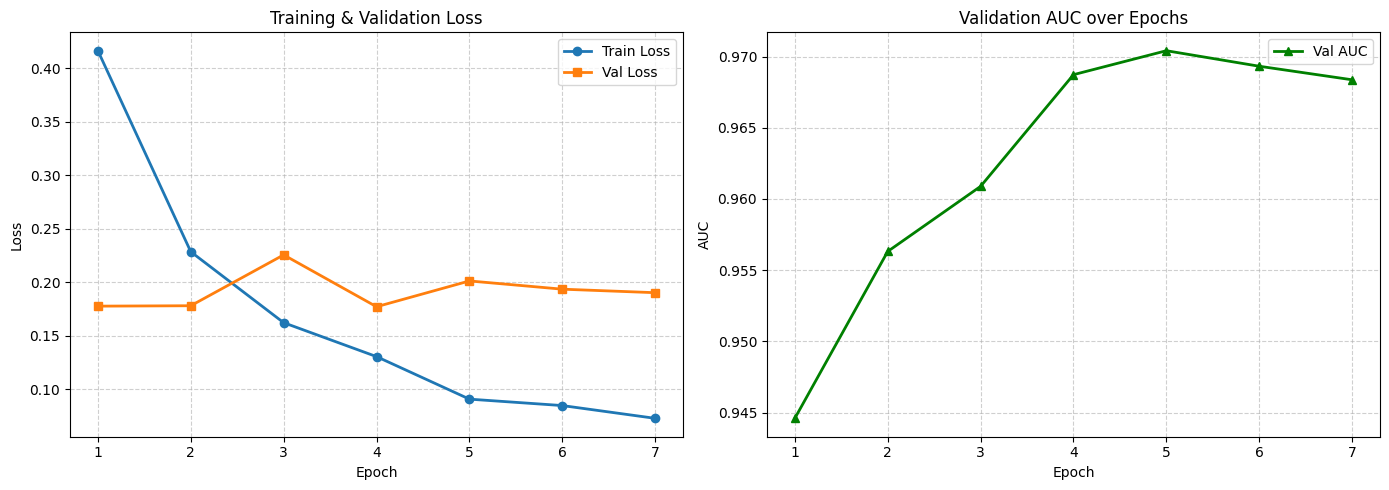

In [ ]:
import matplotlib.pyplot as plt

# رسم منحنيات التدريب والتحقق لمعرفة الـ Overfitting
plt.figure(figsize=(14, 5))

# 1. Loss Curve
plt.subplot(1, 2, 1)
plt.plot(history_df['epoch'], history_df['train_loss'], label='Train Loss', marker='o', linewidth=2)
plt.plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', marker='s', linewidth=2)
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# 2. AUC Curve
plt.subplot(1, 2, 2)
plt.plot(history_df['epoch'], history_df['auc'], label='Val AUC', color='green', marker='^', linewidth=2)
plt.title('Validation AUC over Epochs')
plt.xlabel('Epoch')
plt.ylabel('AUC')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import zipfile


def make_backup_zip(paths, zip_path: Path) -> Path:
    """Pack the given files into one zip and report what was added."""
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in paths:
            if p.is_file():
                zf.write(p, p.name)
                print("added:", p.name, f"({p.stat().st_size / 1e6:.1f} MB)")
            else:
                print("MISSING:", p)
    return zip_path

In [ ]:
from google.colab import files

zip_path = make_backup_zip([
    MODEL_DIR / "best.pth",
    RESULTS_DIR / "thresholds.json",
    RESULTS_DIR / "training_history.csv",
    RESULTS_DIR / "test_predictions.csv",
], Path("/content/image_dna_p4_final.zip"))

files.download(str(zip_path))

added: best.pth (70.9 MB)
added: thresholds.json (0.0 MB)
added: training_history.csv (0.0 MB)
added: test_predictions.csv (0.1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###______________________________
#Grad-CAM & Inference
###______________________________

In [ ]:
def grad_cam(model, input_tensor: torch.Tensor, target_layer) -> np.ndarray:
    """Grad-CAM heat-map (values 0..1) showing what pushed the score towards 'fake'."""
    activations, gradients = [], []

    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(lambda grad: gradients.append(grad))

    handle = target_layer.register_forward_hook(forward_hook)
    try:
        with torch.enable_grad():
            model.zero_grad(set_to_none=True)
            model(input_tensor).squeeze().backward()
    finally:
        handle.remove()

    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations[0]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=input_tensor.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

In [ ]:
def overlay_heatmap(image: Image.Image, cam: np.ndarray, alpha: float = 0.45) -> Image.Image:
    heat = (matplotlib.colormaps["jet"](cam)[..., :3] * 255).astype(np.uint8)
    return Image.blend(image, Image.fromarray(heat).resize(image.size), alpha)

In [ ]:
def encode_png_base64(image: Image.Image) -> str:
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode("ascii")

In [ ]:
MODEL_VERSION = "efficientnet_b4_celebdf_fullframe_v1"


class DeepfakeDetector:
    """Inference interface for Barrier 2: predict(image) -> dict."""

    def __init__(self, weights_path: Path, thresholds_path: Path, device=None, image_size: int = 380):
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.image_size = image_size
        self.model = build_model()
        self.model.load_state_dict(torch.load(weights_path, map_location=self.device))
        self.model.to(self.device).eval()
        with open(thresholds_path) as f:
            thresholds = json.load(f)
        self.low, self.high = thresholds["low"], thresholds["high"]
        _, self.transform = build_transforms(image_size)

    @staticmethod
    def _load(image) -> Image.Image:
        if isinstance(image, (str, Path)):
            image = Image.open(image)
        return image.convert("RGB")

    def _label(self, score: float) -> str:
        if score >= self.high:
            return "fake"
        return "suspicious" if score >= self.low else "real"

    def explain(self, image) -> Image.Image:
        """Grad-CAM overlay on the (resized) input image."""
        image = self._load(image).resize((self.image_size, self.image_size))
        tensor = self.transform(image).unsqueeze(0).to(self.device)
        cam = grad_cam(self.model, tensor, self.model.features[-1])
        return overlay_heatmap(image, cam)

    def predict(self, image, with_heatmap: bool = False) -> dict:
        result = {
            "barrier": "ai_deepfake",
            "model_version": MODEL_VERSION,
            "score": None,
            "label": None,
            "thresholds": {"low": self.low, "high": self.high},
            "heatmap_png_base64": None,
            "error": None,
        }
        try:
            pil_image = self._load(image)
            tensor = self.transform(pil_image).unsqueeze(0).to(self.device)
            with torch.no_grad():
                score = torch.sigmoid(self.model(tensor)).item()
            result["score"], result["label"] = score, self._label(score)
            if with_heatmap:
                result["heatmap_png_base64"] = encode_png_base64(self.explain(pil_image))
        except Exception as exc:
            result["error"] = f"{type(exc).__name__}: {exc}"
        return result

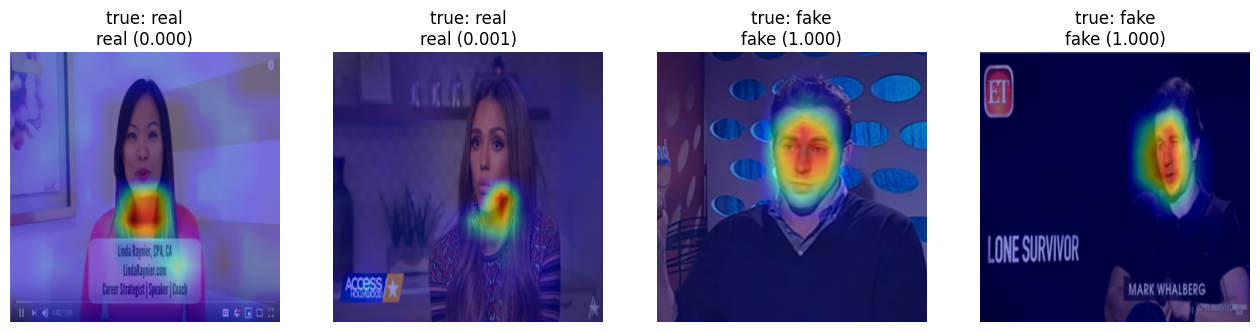

Bad input -> FileNotFoundError: [Errno 2] No such file or directory: 'missing.jpg'


In [ ]:
detector = DeepfakeDetector(MODEL_DIR / "best.pth", RESULTS_DIR / "thresholds.json")

samples = frames_df[frames_df["split"] == "test"].groupby("is_fake").sample(2, random_state=42)
fig, axes = plt.subplots(1, len(samples), figsize=(4 * len(samples), 4))
for ax, row in zip(axes, samples.itertuples()):
    result = detector.predict(row.frame_path)
    ax.imshow(detector.explain(row.frame_path))
    ax.axis("off")
    ax.set_title(f"true: {'fake' if row.is_fake else 'real'}\n{result['label']} ({result['score']:.3f})")
plt.show()

print("Bad input ->", detector.predict("missing.jpg")["error"])

In [ ]:
meta = {
    "model_version": MODEL_VERSION,
    "dataset": "Celeb-DF v2 (full frames, official test list)",
    "input_size": CFG.image_size,
    "thresholds": {"low": low, "high": threshold},
    "test_metrics": {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()},
}
with open(RESULTS_DIR / "model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

In [ ]:
zip_path = make_backup_zip([
    MODEL_DIR / "best.pth",
    RESULTS_DIR / "thresholds.json",
    RESULTS_DIR / "model_meta.json",
    RESULTS_DIR / "training_history.csv",
    RESULTS_DIR / "test_predictions.csv",
], Path("/content/image_dna_p4_final.zip"))

files.download(str(zip_path))

added: best.pth (70.9 MB)
added: thresholds.json (0.0 MB)
added: model_meta.json (0.0 MB)
added: training_history.csv (0.0 MB)
added: test_predictions.csv (0.1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
row = frames_df[(frames_df["split"] == "test") & (frames_df["is_fake"] == 1)].iloc[0]
print(row["frame_path"])
print(detector.predict(row["frame_path"])["score"])

/kaggle/working/frames/test/Celeb-synthesis/id1_id0_0007_f32.jpg
0.9999997615814209


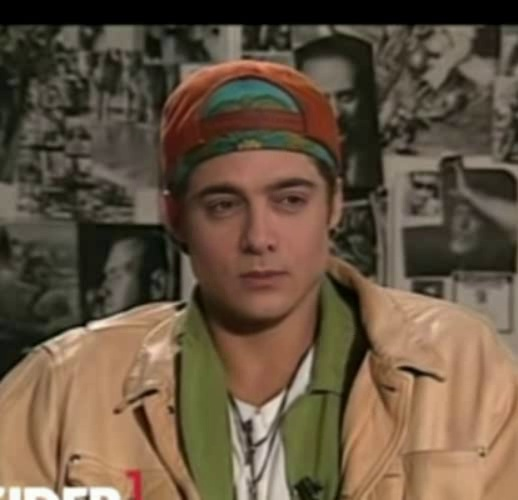

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from PIL import Image

# مسار الصورة المطلوب تنزيلها
img_path = "/kaggle/working/frames/test/Celeb-synthesis/id1_id0_0007_f32.jpg"

# عرض الصورة أولاً للتأكيد
img = Image.open(img_path)
display(img)

# بدء تنزيل الصورة تلقائياً
files.download(img_path)